# interpolation_grid_grid 方法说明

将源格点场重采样到目标水平网格。包内两类入口：

| 系列 | 插件 | 典型用途 |
| --- | --- | --- |
| 等距经纬插值（InterpGg*） | 统一入口 `InterpGg(method=...)` → `Linear` / `Nearest` / `Cubic` / `Conservative` | 等距经纬、融合/背景对齐；越界用 `outer_value` |
| LandSea | `InterpGgLandSea`（及 `InterpGgLandSea2`） | RGI / `*-2` 重网格；可选海陆掩码 |

对外推荐 `InterpGg(method="linear|nearest|cubic|conservative")`。`InterpGgConservative` 为一阶面积加权（对齐 Iris `AreaWeighted`），适合高→低分辨率、需近似守恒的通量类场。

在包根或本 `nbs/` 目录打开本 notebook 即可运行示例（依赖 `meteva_base`、`resource/data`）。

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import meteva_base as meb
import numpy as np
from meteva_base.tool.color_tools import get_cmap_and_clevs_by_element_name

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

PACKAGE_ROOT = Path.cwd().resolve()
if PACKAGE_ROOT.name == "nbs":
    PACKAGE_ROOT = PACKAGE_ROOT.parent
DATA_DIR = PACKAGE_ROOT / "resource" / "data"

src_s, root_s = str(PACKAGE_ROOT / "src"), str(PACKAGE_ROOT)
for p in (src_s, root_s):
    if p in sys.path:
        sys.path.remove(p)
sys.path.insert(0, src_s)
sys.path.insert(0, root_s)

from interp_gg_conservative_plugin import InterpGgConservative
from interp_gg_cubic_plugin import InterpGgCubic
from interp_gg_landsea_plugin import InterpGgLandSea
from interp_gg_plugin import InterpGg
from interp_gg_linear_plugin import InterpGgLinear
from interp_gg_nearest_plugin import InterpGgNearest

# add_mesh 默认按各场数值截断色标。关掉后本页后续 add_mesh 沿用，同一要素图例一致
_ct = meb.tool.color_tools
if not hasattr(_ct, "_orig_def_cmap_clevs"):  # 重复运行本单元时不叠加包装
    _ct._orig_def_cmap_clevs = _ct.def_cmap_clevs
_ct.def_cmap_clevs = lambda *a, cut_colorbar=True, **kw: _ct._orig_def_cmap_clevs(
    *a, cut_colorbar=False, **kw
)

# 预置温度色标（完整色阶）
TEMP_CMAP, TEMP_CLEVS = get_cmap_and_clevs_by_element_name("temp")

# 统一目标网格：所有方法、CLI 示例共用。位于源域内，保证 conservative 边缘格元不被 outer_value 填充
TARGET_LON = [101.5, 122.5, 0.05]
TARGET_LAT = [20.5, 37.5, 0.05]
TARGET_EXTENT = [101.5, 122.5, 20.5, 37.5]  # [lon0, lon1, lat0, lat1]，两张图共用的显示范围


def plot_compare(grd_src, grd_out, title_out, title_src="插值前-源场", map_extend=None, dpi=110):
    """输入源场 + 方法输出场并排绘图：``creat_axs`` 建两格底图，各用 ``add_mesh`` 叠场。

    两图共用同一经纬范围与完整 temp 色标（见上方对 ``def_cmap_clevs`` 的处理），
    便于直接对比；色标条只画在右侧一张图上。

    Parameters
    ----------
    grd_src : 输入源场。
    grd_out : 方法输出场。
    title_out : 输出场子图标题（建议带方法名）。
    title_src : 源场子图标题。
    map_extend : ``[lon0, lon1, lat0, lat1]``；默认取统一目标网格覆盖范围 ``TARGET_EXTENT``。
    """
    if map_extend is None:
        map_extend = TARGET_EXTENT
    titles = [title_src, title_out]
    axs = meb.creat_axs(
        2, map_extend, ncol=2, height=6, width=13, dpi=dpi,
        title_list=titles, wspace=1,grid=False
    )
    for i, grd in enumerate((grd_src, grd_out)):
        meb.add_mesh(
            axs[i], grd, cmap=TEMP_CMAP, clevs=TEMP_CLEVS,
            title=titles[i], title_fontsize=12,
        )
    plt.show()

d:\workspace\test\.venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## 1. 等距经纬插值（InterpGg*）：原理

接口统一为 `process(grd, grid)`：`grd` 为源六维场，`grid` 为目标 `meb.grid`（等距经纬）。
对外推荐 `InterpGg(method=...)`；下表为分派到的各算法。

| 方法 | 原理 |
| --- | --- |
| **InterpGg** | 统一入口：`method=linear/nearest/cubic/conservative` → 对应子插件 |
| **InterpGgLinear** | 目标点映射到源索引分数，取四邻点双线性加权 |
| **InterpGgNearest** | 索引四舍五入到最近源格点赋值 |
| **InterpGgCubic** | 对邻域 `p,q ∈ {-1,0,1,2}` 用三次核 `cubic_f` 加权 |
| **InterpGgConservative** | 正交规则经纬格元重叠面积加权（Iris `AreaWeighted`）；球面用 `Δlon × Δsin(lat)` |

共同约定：

- 源经度跨满 360°（`iscycle`）时经度取模；**纬度越界仍须** `outer_value`。
- 非循环场经纬越界：先插重叠区，再 `expand_to_contain_another_grid` 填外区。
- `member` / `level` / `time` / `dtime` 继承源场；水平网格取自目标 `grid`。
- `attrs` 深拷贝自源场。


## 2. 等距经纬插值（InterpGg*）：参数

| 参数 | 位置 | 说明 |
| --- | --- | --- |
| `method` | 构造 | 仅 `InterpGg`：`linear` / `nearest` / `cubic` / `conservative` |
| `outer_value` | 构造 | 目标超出源域时的填充值；越界且未给则返回 `None` |
| `mdtol` | 构造 | 仅 `conservative`：缺测/覆盖容差 `[0,1]`，默认 `1`（同 Iris） |
| `spherical` | 构造 | 仅 `conservative`：是否按球面面积因子，默认 `True` |
| `grd` | `process` | 源格点场 |
| `grid` | `process` | 目标网格信息（`glon` / `glat` 等） |

CLI（在 `00temp` 目录：`python -m interpolation_grid_grid method=linear|nearest|cubic|conservative ...`，或在包目录：`python -m cli method=...`），缺省读 `resource/conf.ini`；`conservative` 可用 `mdtol=...`、`spherical=true|false`。


## 3. InterpGg 使用示例

推荐写法：`InterpGg(method="linear|nearest|cubic|conservative", ...).process(grd, grid)`。
下面各小节仍演示独立插件；与统一入口等价（`method=` 对应类名后缀）。

**统一目标网格**：所有示例（四种方法、LandSea、CLI）共用同一目标网格 `101.5–122.5°E`、`20.5–37.5°N`、步长 `0.05°`（源场 0.1° 的 2 倍加密），便于直接对比。该网格落在源域内，conservative 的边缘格元不会被 `outer_value` 填充。

**绘图约定**：每个示例都画“输入源场（左）+ 方法输出场（右）”的组合图，便于对比。先用 `meb.creat_axs` 创建两格底图，再对每格用 `meb.add_mesh` 叠加格点场（封装为 `plot_compare`）。`add_mesh` 默认按当前场的数值范围截断色标，会让左右两图图例不一致；第一个代码单元已关闭该截断（包装 `def_cmap_clevs`，强制 `cut_colorbar=False`），两图共用完整 temp 色标，图例一致。

### 3.1 InterpGgLinear使用示例

In [2]:
# 源场：分辨率 0.1°，裁到 101–123°E、20–38°N
grid = meb.read_griddata_from_nc(str(DATA_DIR / "2026100900.024.nc"))
grd_in = grid.sel(lon=slice(101.0, 123.0), lat=slice(20.0, 38.0)) # 网格经纬裁剪
# 统一目标网格（0.05°，落在源域内），所有方法共用
target = meb.basicdata.grid(TARGET_LON, TARGET_LAT)

grd_out_linear = InterpGgLinear(outer_value=0.0).process(grd_in, target)
print(grd_out_linear)

<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 341,
                           lon: 421)> Size: 574kB
array([[[[[[19.2     , 19.45    , 19.7     , ..., 27.5     ,
            27.35    , 27.2     ],
           [19.05    , 19.275   , 19.5     , ..., 27.55    ,
            27.425   , 27.3     ],
           [18.9     , 19.099998, 19.3     , ..., 27.6     ,
            27.5     , 27.4     ],
           ...,
           [-2.8     , -2.35    , -1.9     , ..., 19.4     ,
            19.449999, 19.5     ],
           [-2.5     , -2.525   , -2.55    , ..., 19.35    ,
            19.4     , 19.449999],
           [-2.2     , -2.7     , -3.2     , ..., 19.3     ,
            19.349998, 19.4     ]]]]]],
      shape=(1, 1, 1, 1, 341, 421), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  * dtime    (dtime) int32 4B 24
  * lat      (lat) float64 3kB 20.5 20.55 20.6 20.65 ...

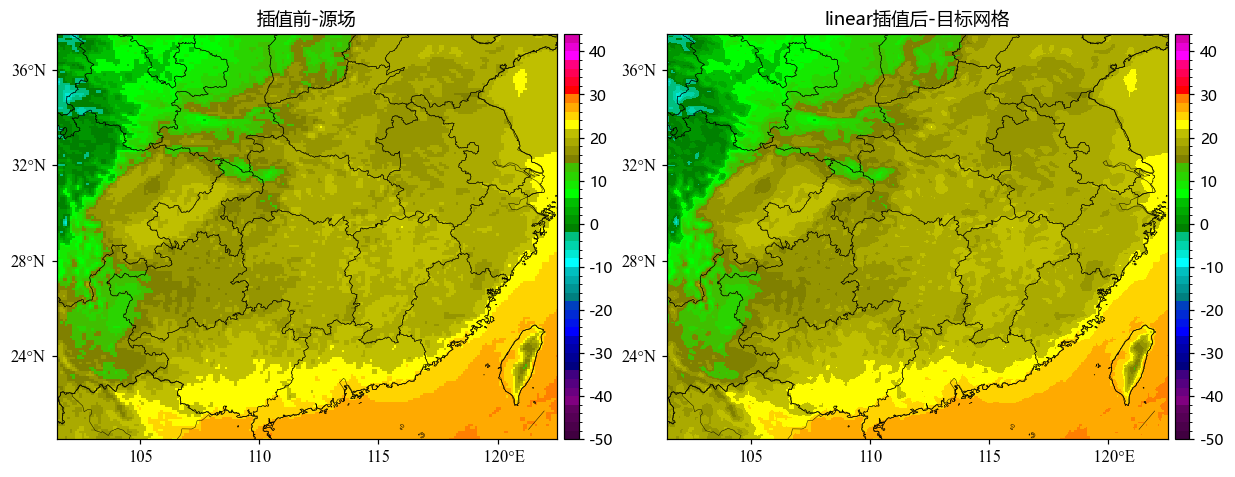

In [3]:
# 源场（左）与 linear 输出场（右）并排对比；图例见首个单元对 add_mesh 色标截断的处理
plot_compare(grd_in, grd_out_linear, "linear插值后-目标网格")

### 3.2 InterpGgNearest使用示例

<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 341,
                           lon: 421)> Size: 574kB
array([[[[[[19.2, 19.2, 19.7, ..., 27.5, 27.2, 27.2],
           [18.9, 18.9, 19.3, ..., 27.6, 27.4, 27.4],
           [18.9, 18.9, 19.3, ..., 27.6, 27.4, 27.4],
           ...,
           [-2.8, -2.8, -1.9, ..., 19.4, 19.5, 19.5],
           [-2.2, -2.2, -3.2, ..., 19.3, 19.4, 19.4],
           [-2.2, -2.2, -3.2, ..., 19.3, 19.4, 19.4]]]]]],
      shape=(1, 1, 1, 1, 341, 421), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  * dtime    (dtime) int32 4B 24
  * lat      (lat) float64 3kB 20.5 20.55 20.6 20.65 ... 37.35 37.4 37.45 37.5
  * lon      (lon) float64 3kB 101.5 101.5 101.6 101.7 ... 122.4 122.5 122.5
Attributes:
    units:        ℃
    model_var:    
    dtime_units:  hour
    level_type:   isobaric
    time_type:    UT
    time_bounds:  [0, 0]


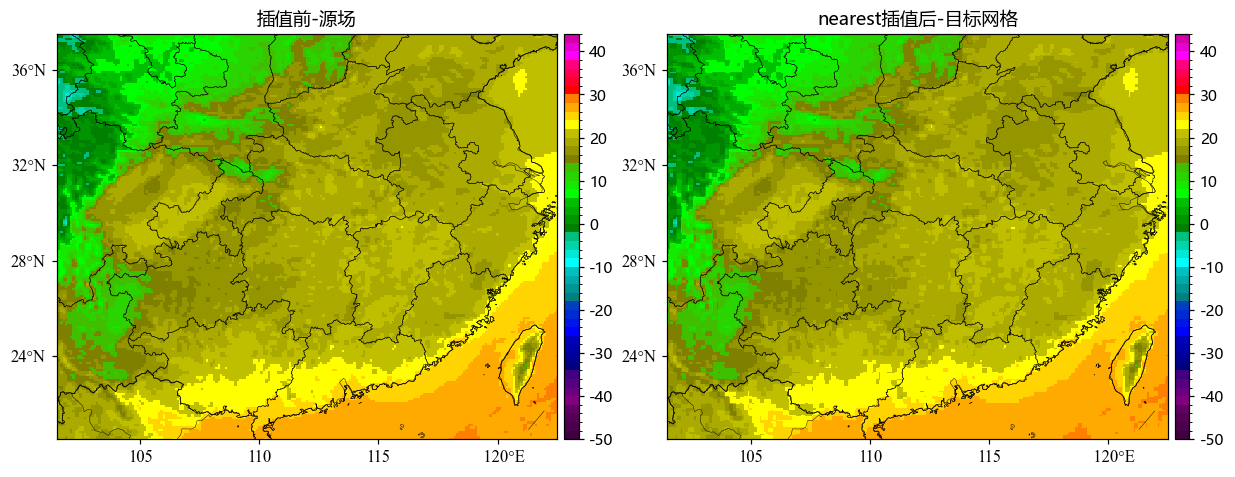

In [4]:
grd_out_nearest = InterpGgNearest(outer_value=0.0).process(grd_in, target)
print(grd_out_nearest)
plot_compare(grd_in, grd_out_nearest, "nearest插值后-目标网格")

### 3.3 InterpGgCubic使用示例

<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 341,
                           lon: 421)> Size: 574kB
array([[[[[[19.2      , 19.468752 , 19.7      , ..., 27.5      ,
            27.337502 , 27.2      ],
           [19.106249 , 19.339453 , 19.562498 , ..., 27.56875  ,
            27.442577 , 27.31875  ],
           [18.9      , 19.0875   , 19.3      , ..., 27.6      ,
            27.50625  , 27.4      ],
           ...,
           [-2.8      , -2.3124998, -1.9      , ..., 19.4      ,
            19.44375  , 19.5      ],
           [-2.125    , -2.111719 , -2.2      , ..., 19.3625   ,
            19.396093 , 19.45     ],
           [-2.2      , -2.65625  , -3.2      , ..., 19.3      ,
            19.3375   , 19.4      ]]]]]],
      shape=(1, 1, 1, 1, 341, 421), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  * dtime    (dtime) int32 4B 24
  * lat      (lat) f

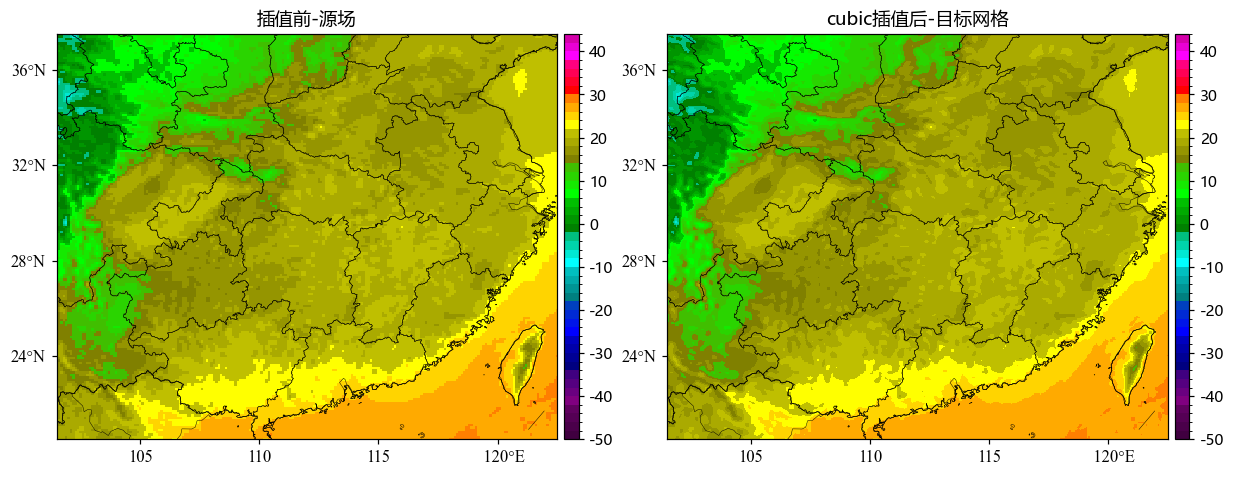

In [5]:
grd_out_cubic = InterpGgCubic(outer_value=0.0).process(grd_in, target)
print(grd_out_cubic)
plot_compare(grd_in, grd_out_cubic, "cubic插值后-目标网格")

### 3.4 InterpGgConservative使用示例

一阶面积加权（AreaWeighted）。核在 `src/utils/area_weighted.py`：由等距中心生成 contiguous 格边，经/纬一维重叠权重外积成稀疏矩阵后做 `data @ W.T`。

下面仍用上文同一份源场，目标为统一的 0.05° 网格。注意：源 0.1° → 目标 0.05° 是 2 倍加密，每个目标格心恰好落在源格心的中点，面积加权与线性插值的权重相同，因此 conservative 与 linear 的结果几乎重合；它与 nearest 的差异来自采样方式。conservative 的守恒优势主要体现在高→低分辨率（见第 7 节选型）。

统一目标网格的每个格元都完全落在源格元覆盖范围内；若格元越出源域边缘，覆盖不足的格元会被 `outer_value` 填充，图上表现为一圈边框。

<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 341,
                           lon: 421)> Size: 574kB
array([[[[[[19.2      , 19.45     , 19.7      , ..., 27.5      ,
            27.35     , 27.2      ],
           [19.050013 , 19.275015 , 19.500017 , ..., 27.549995 ,
            27.424994 , 27.299992 ],
           [18.9      , 19.1      , 19.3      , ..., 27.6      ,
            27.5      , 27.4      ],
           ...,
           [-2.8      , -2.35     , -1.9      , ..., 19.4      ,
            19.449999 , 19.5      ],
           [-2.50005  , -2.5249708, -2.5498915, ..., 19.350008 ,
            19.400007 , 19.450008 ],
           [-2.2      , -2.7      , -3.2      , ..., 19.3      ,
            19.349998 , 19.4      ]]]]]],
      shape=(1, 1, 1, 1, 341, 421), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  * dtime    (dtime) int32 4B 24
  * lat      (lat) f

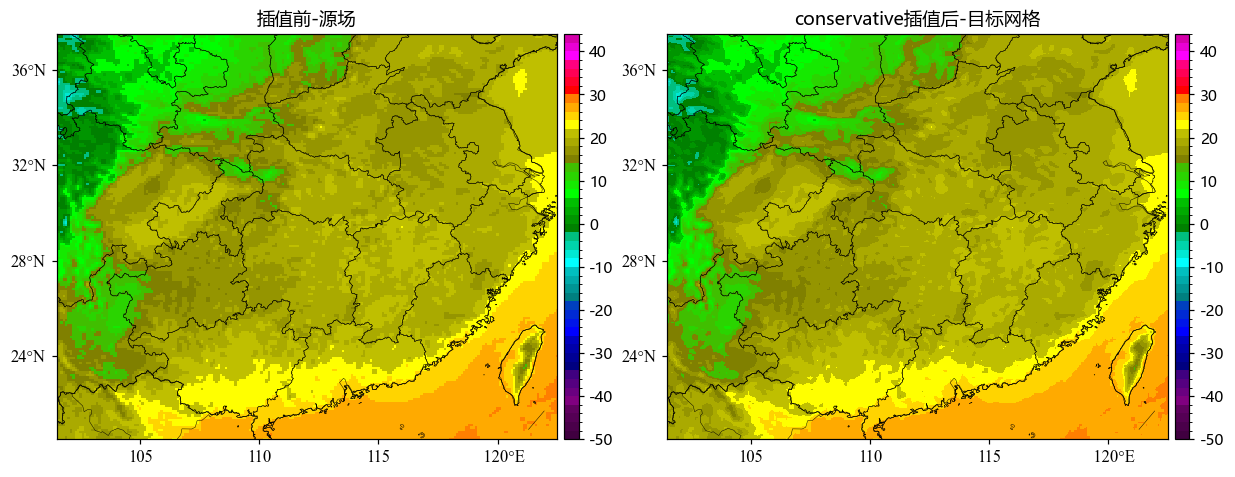

In [6]:
# 源场同上 grd_in；目标同上（统一 0.05° 网格）
grd_out_conservative = InterpGgConservative(
    outer_value=0.0,
    mdtol=1.0,
).process(grd_in, target)
print(grd_out_conservative)
plot_compare(grd_in, grd_out_conservative, "conservative插值后-目标网格")

## 4. LandSea：原理

`InterpGgLandSea` 为统一入口，按 `regrid_mode` 分派：

| `regrid_mode` | 路径 | 掩码 |
| --- | --- | --- |
| `bilinear` / `nearest` | `RegularGridInterpolator`（scipy） | 否 |
| `nearest-with-mask` | 先最近邻，再 `AdjustLandSeaPoints` 订正 | 要源+目标掩码 |
| `bilinear-2` / `nearest-2` | `InterpGgLandSea2` 自研核 | 否 |
| `*-with-mask-2` | `InterpGgLandSea2`：插值时按海陆改邻点/权重 | 要源+目标掩码 |

**掩码约定**：`land_binary_mask`，陆=1、海=0。  
- 源掩码：构造参数 `landmask`。  
- 目标掩码：`process` 的第二参 `target_grid`（掩码模式下该场本身即目标掩码，并提供目标网格）。

`nearest-with-mask`：插值后再用邻域（`landmask_vicinity`，默认 25 km）内同类型最近点替换误取海/陆的点。  
`*-with-mask-2`：在四邻点阶段就按海陆筛选，不是纯后处理。

`extrapolation_mode` 仅作用于 scipy 路径；`*-2` 源域外固定填 NaN，且源场须为经纬度规则网格。业务请始终走 `InterpGgLandSea`（`*-2` 不必直接调 `InterpGgLandSea2`）。

## 5. LandSea：参数

### `InterpGgLandSea`

| 参数 | 说明 |
| --- | --- |
| `regrid_mode` | 见上表；默认 `bilinear` |
| `extrapolation_mode` | 仅 scipy 路径：`nan`（默认）/ `extrapolate` / `error`（别名 mask/nanmask → nan） |
| `landmask` | 源侧海陆掩码；`*-with-mask*` 必需 |
| `landmask_vicinity` | 同类型搜索半径（米），默认 `25000` |
| `process(data, target_grid, regridded_title=None)` | `data` 源场；`target_grid` 目标网格模板（掩码模式为目标掩码场） |

### `InterpGgLandSea2`（一般经 `InterpGgLandSea` 调用）

| 参数 | 说明 |
| --- | --- |
| `regrid_mode` | `bilinear-2` / `nearest-2` / `*-with-mask-2` |
| `vicinity_radius` | 同 `landmask_vicinity` |
| `process(data_in, data_in_mask, data_out_mask)` | 无掩码时 `data_in_mask` 可为 `None` |

CLI（在本包目录）：`python -m cli tran_regrid input_path=... target_grid_path=... [land_sea_mask_path=...] regrid_mode=... [output_path=...]`

## 6. LandSea 使用示例（无掩码）

以预报场为源、HGT 子集为目标网格（仅取空间坐标）。

<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 341,
                           lon: 421)> Size: 574kB
array([[[[[[19.2     , 19.45    , 19.7     , ..., 27.5     ,
            27.35    , 27.2     ],
           [19.05    , 19.275   , 19.5     , ..., 27.55    ,
            27.425   , 27.3     ],
           [18.9     , 19.099998, 19.3     , ..., 27.6     ,
            27.5     , 27.4     ],
           ...,
           [-2.8     , -2.35    , -1.9     , ..., 19.4     ,
            19.449999, 19.5     ],
           [-2.5     , -2.525   , -2.55    , ..., 19.349998,
            19.4     , 19.449999],
           [-2.2     , -2.7     , -3.2     , ..., 19.3     ,
            19.349998, 19.4     ]]]]]],
      shape=(1, 1, 1, 1, 341, 421), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  * dtime    (dtime) int32 4B 24
  * lat      (lat) float64 3kB 20.5 20.55 20.6 20.65 ...

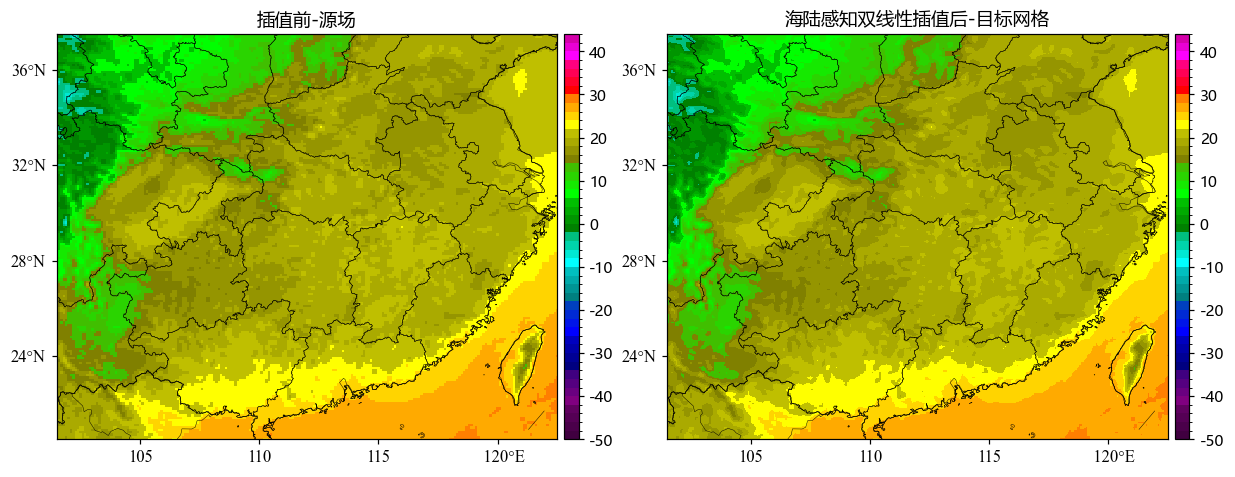

In [7]:
# grd_in / target_grid 为同域或可覆盖的格点场
target_grid = meb.grid_data(target)
grd_out_landsea_bilinear = InterpGgLandSea(
    regrid_mode="bilinear",
    extrapolation_mode="nan",
).process(grd_in, target_grid)
print(grd_out_landsea_bilinear)
plot_compare(grd_in, grd_out_landsea_bilinear, "海陆感知双线性插值后-目标网格")

## 7. 选型建议

- **业务融合 / 背景对齐（meb 等距经纬）**：优先 `InterpGg(method="linear"|"nearest"|"cubic")`，越界用 `outer_value`。
- **高→低分辨率、近似守恒（通量类场）**：`InterpGg(method="conservative")`（AreaWeighted）；可调 `mdtol` / `spherical`；核在 `utils.area_weighted`。
- **与 IMPROVER 海陆模式对齐**：`InterpGgLandSea`；需掩码时准备源、目标两份 `land_binary_mask`。
- 等距经纬、域内：`method="linear"` 与 LandSea `bilinear` 数值接近；最近邻在格心附近可能有格点级差。
- Conservative 仅正交规则经纬网；更多细节见 `docs/interpolation_grid_grid.md`；数值对比见 `nbs/cmp_gg_vs_regrid.ipynb`。


## 8. CLI 使用示例

### 8.1 `interpolation_grid_grid_cli.process`

写出 → D:\workspace\test\00temp\interpolation_grid_grid\resource\data\cli_linear_out.m4
<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 341,
                           lon: 421)> Size: 574kB
array([[[[[[19.2     , 19.45    , 19.7     , ..., 27.5     ,
            27.35    , 27.2     ],
           [19.05    , 19.275   , 19.5     , ..., 27.55    ,
            27.425   , 27.3     ],
           [18.9     , 19.099998, 19.3     , ..., 27.6     ,
            27.5     , 27.4     ],
           ...,
           [-2.8     , -2.35    , -1.9     , ..., 19.4     ,
            19.449999, 19.5     ],
           [-2.5     , -2.525   , -2.55    , ..., 19.349998,
            19.4     , 19.45    ],
           [-2.2     , -2.7     , -3.2     , ..., 19.3     ,
            19.349998, 19.4     ]]]]]],
      shape=(1, 1, 1, 1, 341, 421), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  *

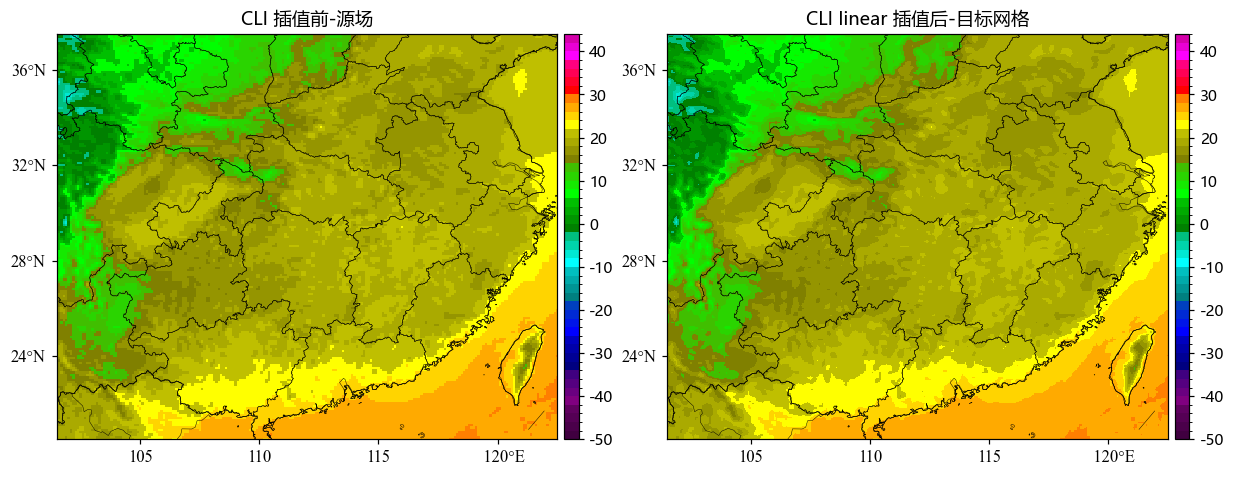

In [8]:
from cli.interpolation_grid_grid_cli import process

input_path = str(DATA_DIR / "2026100900.024.nc")
out_linear = str(DATA_DIR / "cli_linear_out.m4")

# 1) 调度写盘
res = process(
    method="linear",
    grid=input_path,
    output=out_linear,
    glon="101.5, 122.5, 0.05",
    glat="20.5, 37.5, 0.05",
    outer_value=0.0,
    grid_type="nc",
)

# 2) 读输入场与输出场（输入场绘图只绘插值范围）
grid = meb.read_griddata_from_nc(input_path)
grd_in = grid.sel(lon=slice(101.0, 123.0), lat=slice(20.0, 38.0))
result = meb.read_griddata_from_micaps4(out_linear)
print("写出 →", out_linear)
print(result)

plot_compare(grd_in, result, "CLI linear 插值后-目标网格", title_src="CLI 插值前-源场")

#### CLI：`conservative`（面积加权）

与上文同一份输入，目标为统一的 0.05° 网格（`101.5–122.5°E`、`20.5–37.5°N`），写出 Micaps4。

写出 → D:\workspace\test\00temp\interpolation_grid_grid\resource\data\cli_conservative_out.m4
<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 341,
                           lon: 421)> Size: 574kB
array([[[[[[19.2      , 19.45     , 19.7      , ..., 27.5      ,
            27.35     , 27.2      ],
           [19.050013 , 19.275015 , 19.500017 , ..., 27.549995 ,
            27.424994 , 27.299992 ],
           [18.9      , 19.1      , 19.3      , ..., 27.6      ,
            27.5      , 27.4      ],
           ...,
           [-2.8      , -2.35     , -1.9      , ..., 19.4      ,
            19.449999 , 19.5      ],
           [-2.50005  , -2.5249708, -2.5498915, ..., 19.350008 ,
            19.400007 , 19.450008 ],
           [-2.2      , -2.7      , -3.2      , ..., 19.3      ,
            19.349998 , 19.4      ]]]]]],
      shape=(1, 1, 1, 1, 341, 421), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time  

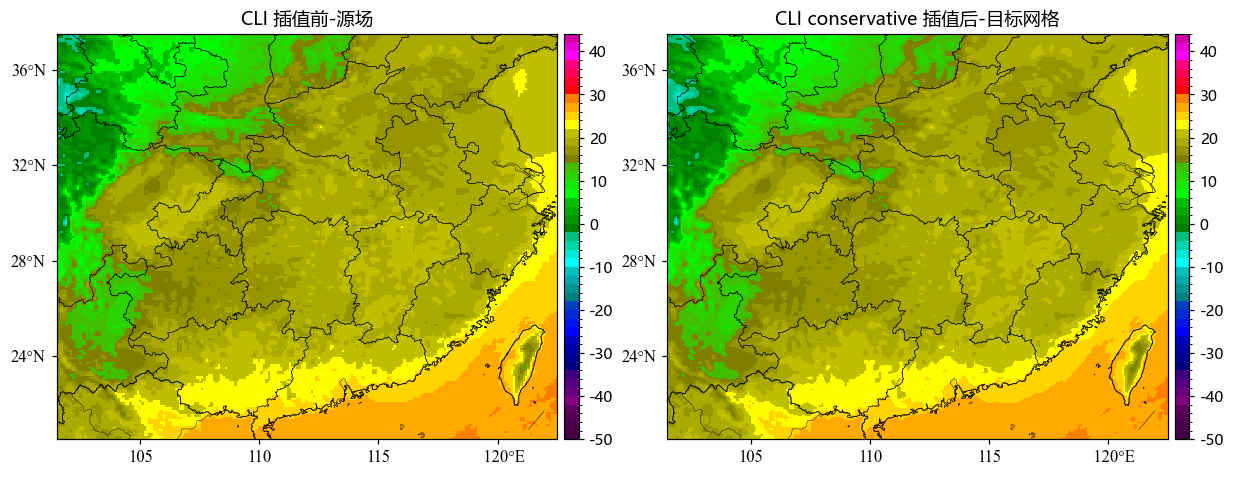

In [9]:
out_conservative = str(DATA_DIR / "cli_conservative_out.m4")

res_c = process(
    method="conservative",
    grid=input_path,
    output=out_conservative,
    glon="101.5, 122.5, 0.05",
    glat="20.5, 37.5, 0.05",
    outer_value=0.0,
    mdtol=1.0,
    spherical=True,
    grid_type="nc",
)

result_c = meb.read_griddata_from_micaps4(out_conservative)
print("写出 →", out_conservative)
print(result_c)
plot_compare(grd_in, result_c, "CLI conservative 插值后-目标网格", title_src="CLI 插值前-源场")

### 8.2 海陆感知重网格 CLI（`tran_regrid_cli.process`）


写出 → D:\workspace\test\00temp\interpolation_grid_grid\resource\data\cli_landsea_bilinear_out.nc
<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 341,
                           lon: 421)> Size: 574kB
array([[[[[[19.2  , 19.45 , 19.7  , ..., 27.5  , 27.35 , 27.2  ],
           [19.05 , 19.275, 19.5  , ..., 27.55 , 27.425, 27.3  ],
           [18.9  , 19.1  , 19.3  , ..., 27.6  , 27.5  , 27.4  ],
           ...,
           [-2.8  , -2.35 , -1.9  , ..., 19.4  , 19.45 , 19.5  ],
           [-2.5  , -2.525, -2.55 , ..., 19.35 , 19.4  , 19.45 ],
           [-2.2  , -2.7  , -3.2  , ..., 19.3  , 19.35 , 19.4  ]]]]]],
      shape=(1, 1, 1, 1, 341, 421), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-10-09
  * dtime    (dtime) int32 4B 24
  * lat      (lat) float64 3kB 20.5 20.55 20.6 20.65 ... 37.35 37.4 37.45 37.5
  * lon      (lon) float64 3kB 101.5 101.5 101.6 101.7 ... 12

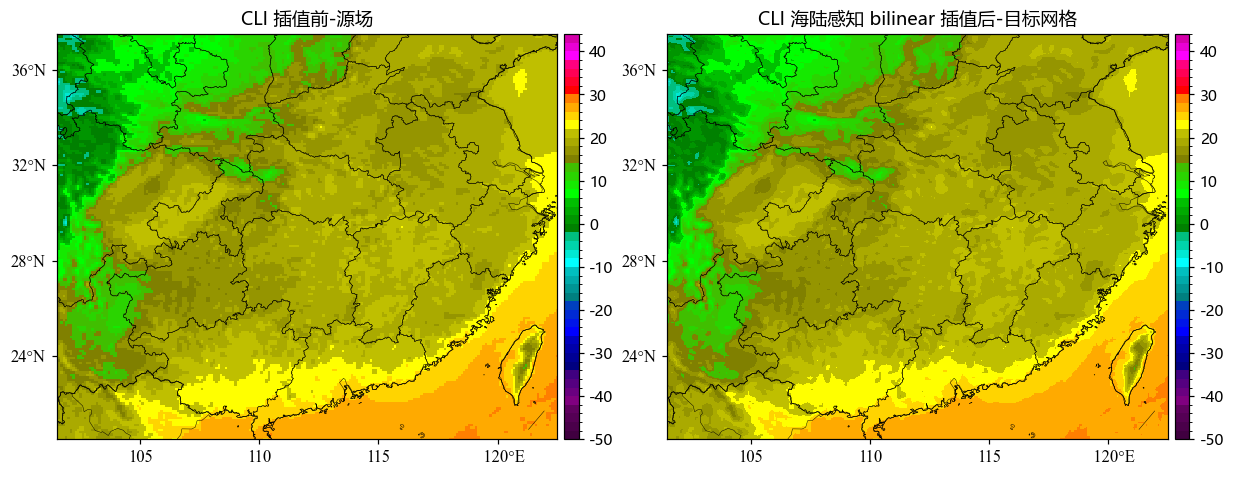

In [10]:
from cli.tran_regrid_cli import process as tran_regrid

input_path = str(DATA_DIR / "2026100900.024.nc")
target_grid_path = str(DATA_DIR / "cli_target_grid.nc")
meb.write_griddata_to_nc(meb.grid_data(target), target_grid_path, creat_dir=True)  # 统一目标网格
out_landsea = str(DATA_DIR / "cli_landsea_bilinear_out.nc")

# 1) 调度写盘
tran_regrid(
    input_path=input_path,
    target_grid_path=target_grid_path,
    output_path=out_landsea,
    land_sea_mask_path=None,
    regrid_mode="bilinear",
    extrapolation_mode="nan",
)

# 2) 读输入场与输出场（输入场绘图只绘插值范围）
grid = meb.read_griddata_from_nc(input_path)
grd_in = grid.sel(lon=slice(101.0, 123.0), lat=slice(20.0, 38.0))
result = meb.read_griddata_from_nc(out_landsea)
print("写出 →", out_landsea)
print(result)

plot_compare(grd_in, result, "CLI 海陆感知 bilinear 插值后-目标网格", title_src="CLI 插值前-源场")